# 04 — Régression logistique interprétable
Objectif : décrire des associations ajustées et évaluer une prédiction exploratoire des départs. Le modèle ne permet pas de choisir des salariés à cibler ni d’estimer les effets d’une action RH.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "data.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "src" / "data.py").exists():
    raise RuntimeError("Lancer depuis la racine du projet ou notebooks/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.data import load_data, export_table, attrition_table
from src.plots import plot_attrition, save_figure
df = load_data()


## Variables et exclusion des identifiants
Choix limité de variables pour conserver la lisibilité et éviter des mesures salariales redondantes. Les identifiants et constantes sont exclus. Les scores et niveaux sont traités en catégories, car les échelles ne sont pas validées. Les anciennetés peuvent être corrélées. Le genre sert à l’audit des écarts ; son coefficient n’est pas un diagnostic de discrimination.

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score, brier_score_loss, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay)
cat = ["Gender", "JobRole", "JobLevel", "OverTime", "BusinessTravel", "WorkLifeBalance"]
cat += [c for c in df if "Satisfaction" in c]
num = ["Age", "MonthlyIncome", "DistanceFromHome", "TotalWorkingYears", "YearsAtCompany", "YearsSinceLastPromotion"]
X, y = df[cat + num].copy(), df.depart
assert not {"EmployeeNumber", "EmployeeCount", "Over18", "StandardHours", "Attrition", "depart"}.intersection(X.columns)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.25, stratify=y, random_state=42)
display(pd.DataFrame({"effectif": [len(y_train), len(y_test)], "departs": [y_train.sum(), y_test.sum()], "proportion": [y_train.mean(), y_test.mean()]}, index=["entraînement", "test"]))

,effectif,departs,proportion
entraînement,1138,186,0.163445
test,380,62,0.163158


## Prétraitement appris uniquement sur l’entraînement
Imputation, standardisation, catégories de référence et filtrage des constantes sont ajustés dans le pipeline après le découpage. Aucune sélection par performance du test. La pénalisation L2 stabilise les coefficients ; aucun intervalle de confiance classique n’est attaché à ces estimations pénalisées.

In [3]:
numeric = Pipeline([("imputation", SimpleImputer(strategy="median")), ("echelle", StandardScaler())])
categorical = Pipeline([("imputation", SimpleImputer(strategy="most_frequent")),
                        ("encodage", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))])
prep = ColumnTransformer([("num", numeric, num), ("cat", categorical, cat)])
model = Pipeline([("preparation", prep), ("constantes", VarianceThreshold()),
                  ("logistique", LogisticRegression(C=1, max_iter=3000, random_state=42))])
model.fit(X_train, y_train)
print("Itérations :", model.named_steps["logistique"].n_iter_)
print("Paramètres numériques standardisés ; catégories comparées à leur référence.")

Itérations : [45]
Paramètres numériques standardisés ; catégories comparées à leur référence.


## Évaluation sur le test réservé
Seuil fixé à 0,5. Comparaison à une prédiction constante de prévalence apprise sur l’entraînement. L’accuracy équilibrée et la précision-rappel éclairent le déséquilibre des classes. Un seul découpage donne des résultats incertains.

,modele,roc_auc,average_precision,accuracy_equilibree,precision,rappel,f1,brier
0,Logistique,0.833283,0.646517,0.685687,0.827586,0.387097,0.527473,0.093913
1,Référence,0.500000,0.163158,0.500000,0.000000,0.000000,0.000000,0.136537


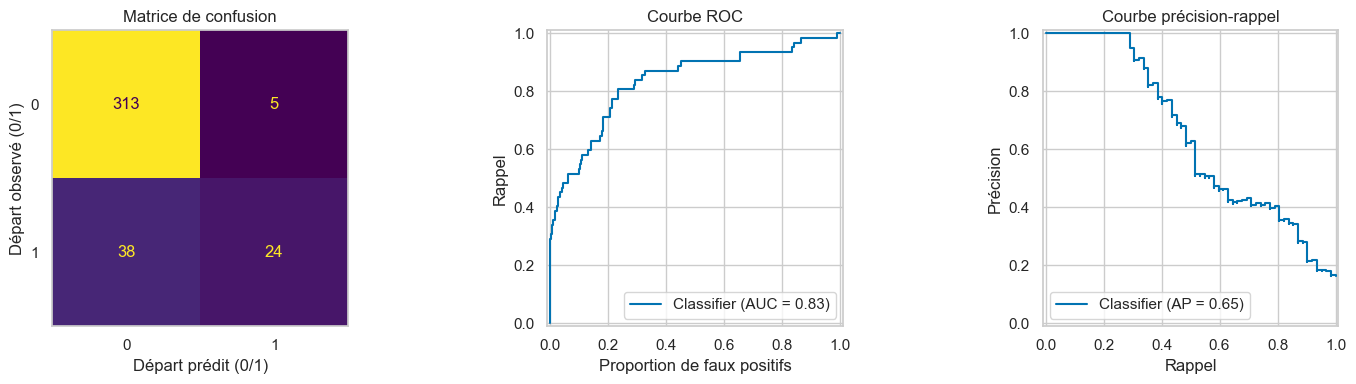

Au seuil 0,5 : 38.7% des départs du test sont détectés.
Une bonne AUC ne garantit donc pas un rappel élevé au seuil choisi.


In [4]:
baseline = DummyClassifier(strategy="prior").fit(X_train, y_train)
rows = []
for nom, estimateur in [("Logistique", model), ("Référence", baseline)]:
    proba = estimateur.predict_proba(X_test)[:, 1]
    pred = (proba >= .5).astype(int)
    rows.append({"modele": nom, "roc_auc": roc_auc_score(y_test, proba),
                 "average_precision": average_precision_score(y_test, proba),
                 "accuracy_equilibree": balanced_accuracy_score(y_test, pred),
                 "precision": precision_score(y_test, pred, zero_division=0),
                 "rappel": recall_score(y_test, pred), "f1": f1_score(y_test, pred),
                 "brier": brier_score_loss(y_test, proba)})
display(export_table(pd.DataFrame(rows), "04_evaluation"))
proba = model.predict_proba(X_test)[:, 1]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay.from_predictions(y_test, proba >= .5, ax=axes[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[1])
PrecisionRecallDisplay.from_predictions(y_test, proba, ax=axes[2])
axes[0].set(xlabel="Départ prédit (0/1)", ylabel="Départ observé (0/1)", title="Matrice de confusion")
axes[0].grid(False)
axes[1].set(xlabel="Proportion de faux positifs", ylabel="Rappel", title="Courbe ROC")
axes[2].set(xlabel="Rappel", ylabel="Précision", title="Courbe précision-rappel")
save_figure(fig, "04_evaluation")
print(f"Au seuil 0,5 : {recall_score(y_test, proba >= .5):.1%} des départs du test sont détectés.")
print("Une bonne AUC ne garantit donc pas un rappel élevé au seuil choisi.")

## Coefficients et rapports de cotes
Un rapport de cotes (`odds ratio`) supérieur à 1 indique des cotes de départ plus élevées, conditionnellement aux autres variables. Il ne s’agit pas d’un risque relatif. Pour les nombres, la variation est d’un écart-type de l’entraînement ; pour les catégories, la comparaison se fait à la référence affichée.

,variable,coefficient,odds_ratio
16,cat__JobLevel_2,-1.014039,0.362751
11,cat__JobRole_Research Director,-0.900133,0.406516
37,cat__JobSatisfaction_4,-0.656950,0.518430
25,cat__WorkLifeBalance_3,-0.605019,0.546064
38,cat__JobSatisfaction_5,-0.477960,0.620047
18,cat__JobLevel_4,-0.452280,0.636176
4,num__YearsAtCompany,-0.413291,0.661469
24,cat__WorkLifeBalance_2,-0.410928,0.663034
42,cat__RelationshipSatisfaction_4,-0.378195,0.685097
31,cat__EnvironmentSatisfaction_3,-0.371227,0.689887


,variable,reference
0,Gender,Female
1,JobRole,Healthcare Representative
2,JobLevel,0
3,OverTime,No
4,BusinessTravel,Non-Travel
5,WorkLifeBalance,0
6,EnvironmentSatisfaction,0
7,JobSatisfaction,0
8,RelationshipSatisfaction,0


,variable,moyenne_train,ecart_type_train
0,Age,37.159930,9.304406
1,MonthlyIncome,6511.800527,4639.604768
2,DistanceFromHome,9.148506,8.150490
3,TotalWorkingYears,11.322496,7.731128
4,YearsAtCompany,7.071178,6.138074
5,YearsSinceLastPromotion,2.224077,3.273135


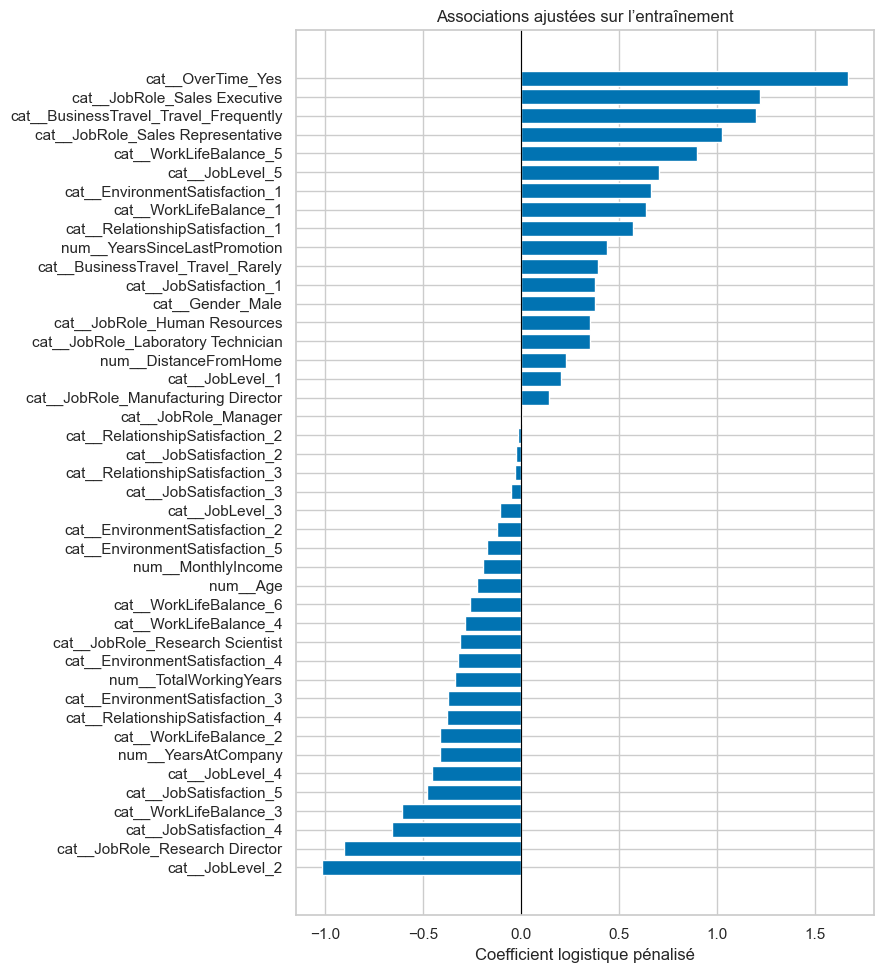

In [5]:
names = model.named_steps["preparation"].get_feature_names_out()
mask = model.named_steps["constantes"].get_support()
coef = pd.DataFrame({"variable": names[mask], "coefficient": model.named_steps["logistique"].coef_[0]})
coef["odds_ratio"] = np.exp(coef.coefficient)
coef = coef.sort_values("coefficient")
display(export_table(coef, "04_coefficients"))
encoder = model.named_steps["preparation"].named_transformers_["cat"].named_steps["encodage"]
references = pd.DataFrame({"variable": cat, "reference": [v[0] for v in encoder.categories_]})
display(export_table(references, "04_references"))
scaler = model.named_steps["preparation"].named_transformers_["num"].named_steps["echelle"]
display(export_table(pd.DataFrame({"variable": num, "moyenne_train": scaler.mean_, "ecart_type_train": scaler.scale_}), "04_echelles"))
fig, ax = plt.subplots(figsize=(9, max(5, len(coef)*.23)))
ax.barh(coef.variable, coef.coefficient)
ax.axvline(0, color="black", linewidth=.8)
ax.set(xlabel="Coefficient logistique pénalisé", title="Associations ajustées sur l’entraînement")
save_figure(fig, "04_coefficients")

## Limites et recommandations pour la suite
Les variables ont été observées à une date inconnue ; leur disponibilité avant le départ n’est pas établie. Cette possible fuite temporelle limite la portée prédictive, même avec un prétraitement correctement séparé. Les scores atypiques et incohérences d’ancienneté demandent une validation métier. La colinéarité et les modalités rares fragilisent les coefficients.

La pénalisation n’est pas un test de significativité. Les analyses multiples sont exploratoires. Il manque notamment les dates, pays, recrutements, promotions et temps de travail ; la généralisation à l’Afrique n’est pas démontrée. Avant un usage opérationnel : valider les définitions, répéter les mesures, évaluer sur une cohorte ultérieure et auditer la performance par groupe avec des effectifs suffisants.

Pour l’expansion, prioriser des pilotes RH collectifs sur la charge, les déplacements et la transparence des parcours, selon les résultats descriptifs et les retours terrain. Fixer des indicateurs datés et un protocole d’évaluation avant déploiement. Les associations de ce modèle ne prouvent pas l’efficacité de ces actions.